[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/kse/MATH840/26autumn/labs/_demo08_uk.ipynb)

# MATH840 — практика тижня 8: сезонна ARIMA у чотирьох реальних історіях

**Українська версія з повним розбором.** Код той самий, що в англомовному ноутбуці
[`_demo08.ipynb`](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/kse/MATH840/26autumn/labs/_demo08.ipynb);
тут після кожного кроку записано, що саме видно в результатах, а на кожне питання для обговорення дано
відповідь. Усі числа в тексті — з виконання цього ноутбука.

Заняття **не оцінюється**. Матеріал — лекція *ARIMA Models, Part 2*. Сьогоднішня Lab 7 — це кейс 1 на
вашому власному ряді.

| Кейс | Історія | Чого вчить |
|---|---|---|
| 0 | — | інструменти, тепер із сезонними членами |
| 1 | ✈️ Пасажири авіаліній, 1949–1960 | найвідоміша сезонна ARIMA, прочитана прямо з ACF |
| 2 | 🌍 CO₂ на Мауна-Лоа | модель, побудована у 2000 році, перевірена у 2026-му |
| 3 | 🏭 Шість австралійських галузей | ARIMA проти ETS: хто виграє і як часто |
| 4 | 🔥 Спека в Мельбурні, січень 2014 | регресія з ARIMA-похибками на межі своїх даних |

## 0. Налаштування та інструменти

In [1]:
!pip install -q statsforecast==2.1.1

import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import warnings
warnings.filterwarnings("ignore")
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsforecast import StatsForecast
from statsforecast.arima import ARIMASummary, ndiffs, nsdiffs
from statsforecast.models import ARIMA, AutoARIMA, AutoETS, SeasonalNaive
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mase

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

BASE = ("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/"
        "main/lectures/kse/MATH840/26autumn/data")
COLOURS = {"actual": "#314f4f", "a": "#e64173", "b": "#20B2AA", "c": "#FFA500", "d": "#6A5ACD"}

Ті самі чотири кроки, що й на тижні 7, з однією зміною: сезонні лаги тепер **читаємо**, а не лише
розглядаємо, а `compare` рахує для тесту Люнга–Бокса $p + q + P + Q$ ступенів свободи.

1. `difference_plan` — спершу сезонна різниця $D$ (за силою сезонності), потім звичайна $d$ (KPSS).
2. `acf_pacf` — ACF і PACF продиференційованого ряду; сезонні лаги $m, 2m, 3m$ підсвічено.
3. `compare` — AICc і Люнг–Бокс для кожного кандидата.
4. `rolling` — MASE на кількох ковзних початках.

In [2]:
def difference_plan(y, m):
    # Крок 1: D за силою сезонності, потім d за KPSS на тому, що залишилось.
    D = nsdiffs(y, period=m)
    z = y[m:] - y[:-m] if D else y.copy()
    d = ndiffs(z)
    z = np.diff(z, n=d) if d else z
    print(f"D = {D}, d = {d}: {len(y)} спостережень -> {len(z)} після диференціювання")
    return D, d, z


def acf_pacf(z, lags, title="", m=None):
    # Крок 2: графіки, з яких читаємо p, q (перші лаги) і P, Q (лаги m, 2m, 3m).
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
    plot_acf(z, lags=lags, zero=False, ax=axes[0], auto_ylims=True, title=f"{title} ACF")
    plot_pacf(z, lags=lags, zero=False, ax=axes[1], auto_ylims=True, title=f"{title} PACF")
    if m:
        for ax in axes:
            for k in range(m, lags + 1, m):
                ax.axvline(k, color="#e64173", alpha=0.25, linewidth=6)   # сезонні лаги
    plt.show()


def compare(y, candidates):
    # Крок 3: AICc і Люнг–Бокс (2m лагів, model_df = p + q + P + Q) для кожного кандидата.
    rows = []
    for name, model in candidates.items():
        fit = model.fit(y=y)
        p, q, P, Q, m = fit.model_["arma"][:5]
        lb = acorr_ljungbox(fit.model_["residuals"], lags=[2 * max(m, 1)], model_df=p + q + P + Q)
        rows.append({"кандидат": name, "модель": str(ARIMASummary(fit.model_)).strip(),
                     "AICc": fit.model_["aicc"], "Люнг–Бокс p": lb["lb_pvalue"].iloc[0]})
    return pd.DataFrame(rows).sort_values("AICc")


def rolling(df, models, h, m, windows):
    # Крок 4: MASE на `windows` ковзних початках, по h кроків кожен.
    cv = StatsForecast(models=models, freq=pd.infer_freq(df["ds"])).cross_validation(
        df=df, h=h, n_windows=windows, step_size=h)
    out = evaluate(cv.drop(columns="cutoff"), metrics=[partial(mase, seasonality=m)], train_df=df)
    return out.drop(columns=["unique_id", "metric"]).T.rename(columns={0: "MASE"}).sort_values("MASE")

## 1. ✈️ Пасажири міжнародних авіаліній, 1949–1960

Щомісячна кількість пасажирів, тисячі осіб. 1970 року Бокс і Дженкінс показали на цьому ряді, на що
здатна ARIMA; знайдену ними модель досі називають **моделлю авіаліній** (airline model).

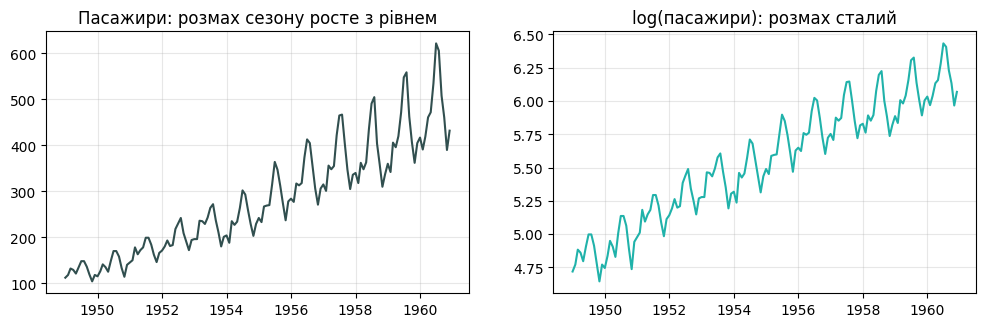

In [3]:
air = pd.read_csv(f"{BASE}/air_passengers.csv", parse_dates=["ds"]).assign(unique_id="air")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(air["ds"], air["y"], color=COLOURS["actual"])
axes[0].set_title("Пасажири: розмах сезону росте з рівнем")
axes[1].plot(air["ds"], np.log(air["y"]), color=COLOURS["b"])
axes[1].set_title("log(пасажири): розмах сталий")
plt.show()

**Висновок.** Ліворуч сезонні коливання 1960 року в кілька разів ширші, ніж у 1949-му: сезонність
**мультиплікативна**. Праворуч, після логарифма, розмах однаковий упродовж усього ряду — сезонність стала
адитивною. ARIMA не має мультиплікативного сезону, тож цю роботу робить логарифм (тиждень 7). Далі все
— на $\log y$.

D = 1, d = 1: 144 спостережень -> 131 після диференціювання


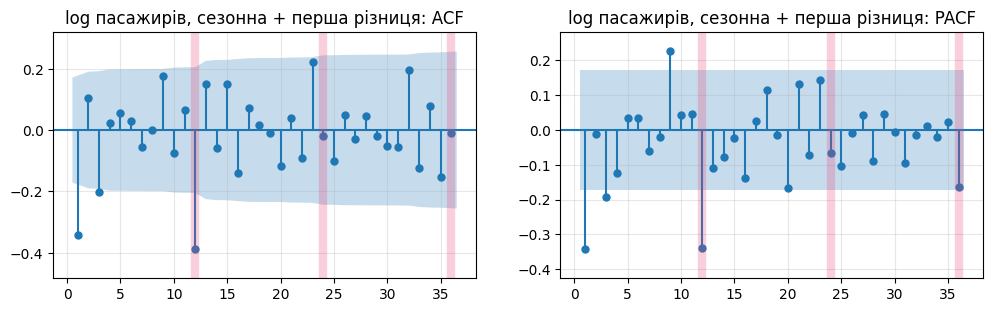

In [4]:
log_air = air.assign(y=np.log(air["y"]))
y1 = log_air["y"].to_numpy()
D1, d1, z1 = difference_plan(y1, m=12)
acf_pacf(z1, lags=36, title="log пасажирів, сезонна + перша різниця:", m=12)

**Висновок: читаємо модель з графіків.**

- **Різниці.** Тест сили сезонності дає $D = 1$, KPSS на сезонно продиференційованому ряді — $d = 1$.
  Разом $d + D = 2$: ряд має і тренд, і сезон, що повільно змінюється.
- **Несезонна частина.** На ACF — один значущий від'ємний стрибок на лагу 1 (близько −0,34), далі в межах
  смуги. PACF на перших лагах спадає поступово. Обрив ACF після лагу 1 — це **MA(1)**: $p = 0, q = 1$.
- **Сезонна частина.** На підсвіченому лагу 12 ACF знову має від'ємний стрибок (близько −0,39), а на 24 і 36
  — нічого. Обрив на першому сезонному лагу — це **сезонний MA(1)**: $P = 0, Q = 1$.

Прочитана модель: $\text{ARIMA}(0,1,1)(0,1,1)_{12}$ на $\log y$. Від'ємні стрибки на лагах 1 і 12 —
типовий слід двох різниць: диференціювання «перестаралося», і MA-члени це компенсують.

In [5]:
seasonal = partial(ARIMA, season_length=12)
compare(y1, {
    "вручну: модель авіаліній": seasonal(order=(0, 1, 1), seasonal_order=(0, 1, 1)),
    "вручну: AR замість MA": seasonal(order=(1, 1, 0), seasonal_order=(1, 1, 0)),
    "AutoARIMA, stepwise": AutoARIMA(season_length=12),
    "AutoARIMA, повний пошук": AutoARIMA(season_length=12, stepwise=False),
})

,кандидат,модель,AICc,Люнг–Бокс p
0,вручну: модель авіаліній,"ARIMA(0,1,1)(0,1,1)[12]",-483.103,0.213
2,"AutoARIMA, stepwise","ARIMA(0,1,1)(0,1,1)[12]",-483.103,0.213
3,"AutoARIMA, повний пошук","ARIMA(0,1,1)(0,1,1)[12]",-483.103,0.213
1,вручну: AR замість MA,"ARIMA(1,1,0)(1,1,0)[12]",-474.371,0.018


**Висновок.** І покроковий (stepwise), і повний пошук `AutoARIMA` знаходять **ту саму** модель
$(0,1,1)(0,1,1)_{12}$, що й ручне читання, з найменшим AICc. Тест Люнга–Бокса для неї не відхиляє білий
шум (p ≈ 0,2). Альтернатива з AR-членами замість MA гірша за AICc і, головне, лишає автокореляцію в
залишках: p < 0,05. Прочитати MA там, де ACF обривається, — правильний хід.

Порівнювати AICc тут коректно: в усіх кандидатів однакові $d$, $D$ і та сама трансформація.

{'ma1': -0.377, 'sma1': -0.572}  — Бокс і Дженкінс (1970): -0.40 і -0.61


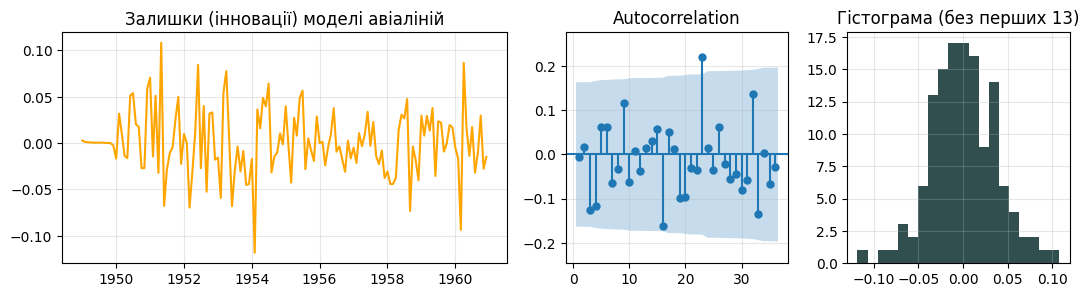

In [6]:
airline = seasonal(order=(0, 1, 1), seasonal_order=(0, 1, 1)).fit(y=y1)
print({k: round(float(v), 3) for k, v in airline.model_["coef"].items()},
      " — Бокс і Дженкінс (1970): -0.40 і -0.61")

resid = airline.model_["residuals"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3), width_ratios=[2, 1, 1])
axes[0].plot(air["ds"], resid, color=COLOURS["c"])
axes[0].set_title("Залишки (інновації) моделі авіаліній")
plot_acf(resid, lags=36, zero=False, ax=axes[1], auto_ylims=True)
axes[2].hist(resid[13:], bins=20, color=COLOURS["actual"])
axes[2].set_title("Гістограма (без перших 13)")
plt.show()

**Висновок.** Оцінки $\theta$ і $\Theta$ близькі до опублікованих Боксом і Дженкінсом. Невеликі розбіжності
дає інший метод оцінювання, а не інша модель.

Залишки схожі на білий шум: немає тренду, немає сезонного візерунка. На ACF лише один лаг із 36 — лаг 23 —
трохи виходить за смугу; при рівні 5% одного-двох таких випадкових перевищень і слід очікувати, а на
сезонних лагах 12, 24 і 36 нічого немає. Люнг–Бокс (p ≈ 0,21) підтверджує те саме. Гістограма приблизно
симетрична. Перші 13 залишків відкидаємо: це «розігрів»
двох різниць (1 + 12 спостережень), а не похибки моделі. Отже, модель забрала з ряду всю структуру, яку
можна побачити, і інтервали прогнозу можна вважати чесними.

In [7]:
rolling(log_air,
        [seasonal(order=(0, 1, 1), seasonal_order=(0, 1, 1), alias="модель авіаліній"),
         AutoETS(season_length=12, alias="ETS"),
         SeasonalNaive(season_length=12, alias="snaive")],
        h=12, m=12, windows=3)

,MASE
модель авіаліній,0.465
ETS,0.489
snaive,0.705


**Висновок.** На трьох ковзних початках (три останні роки, по 12 місяців) модель авіаліній має найменшу
MASE. ETS поступається їй трохи, сезонний наївний прогноз — суттєво. AICc обирав серед ARIMA, а ковзний
початок підтвердив вибір **на прогнозах** і порівняв його з іншою родиною моделей. AICc такого
порівняння зробити не може.

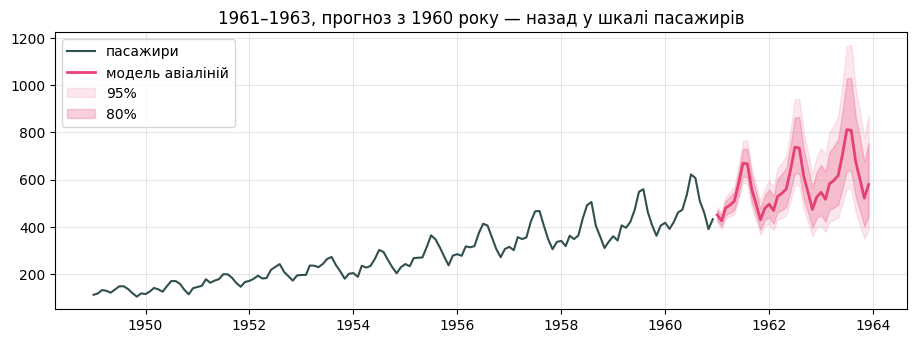

In [8]:
fc = airline.predict(h=36, level=[80, 95])
future = pd.date_range(air["ds"].iloc[-1], periods=37, freq="MS")[1:]
fig, ax = plt.subplots()
ax.plot(air["ds"], air["y"], color=COLOURS["actual"], label="пасажири")
ax.plot(future, np.exp(fc["mean"]), color=COLOURS["a"], linewidth=2, label="модель авіаліній")
for level, alpha in [(95, 0.12), (80, 0.25)]:
    ax.fill_between(future, np.exp(fc[f"lo-{level}"]), np.exp(fc[f"hi-{level}"]),
                    color=COLOURS["a"], alpha=alpha, label=f"{level}%")
ax.set_title("1961–1963, прогноз з 1960 року — назад у шкалі пасажирів")
ax.legend(loc="upper left")
plt.show()

### Обговорення і відповіді

**Два коефіцієнти і дві різниці описують дванадцять років авіаперевезень. Ручне читання, stepwise і повний
пошук дійшли однієї моделі. Коли так буває — і чому це має додавати впевненості, але не знімати
обережності?**

Так буває, коли сигнал в ACF сильний і чистий: один стрибок на лагу 1, один на лагу 12, решта — шум. Тоді
і людина, і алгоритм бачать те саме. Збіг означає, що **структуру** визначено надійно. Але він нічого не
каже про те, чи модель добре прогнозує, і не гарантує, що майбутнє буде схоже на минуле. Тому ми все одно
перевірили залишки (білий шум) і ковзний початок (модель виграла). У Lab 7 збіг ручної моделі з
`AutoARIMA` — гарний аргумент для 3.2, але не заміна 3.3.

**Інтервал розширюється праворуч і асиметричний. Яке рішення моделі дає кожну з цих властивостей?**

- **Розширення** — від $d + D = 2$: дві різниці накопичують невизначеність і рівня, і нахилу, тож дисперсія
  похибки росте з горизонтом без межі.
- **Асиметрія** — від логарифма: у шкалі $\log y$ інтервал симетричний, а $\exp(\cdot)$ розтягує верхню межу
  сильніше за нижню. Крім того, $\exp$ від середнього прогнозу в логах — це медіана, а не середнє в шкалі
  пасажирів; для 80% і 95% меж це неважливо, бо квантилі при монотонному перетворенні зберігаються.

## 2. 🌍 CO₂ на Мауна-Лоа: прогноз 2000 року, перевірений у 2026-му

Найдовший безперервний ряд концентрації CO₂ в атмосфері, щомісяця з 1958 року, частки на мільйон (ppm),
дані NOAA. Питання: **стоячи у грудні 2000 року, маючи лише дані до того моменту, що ви спрогнозували б на
сьогодні — і наскільки помилилися б?** На відміну від майже будь-якого прогнозу, цей можна перевірити на 25
роках.

навчання: 514 місяців до 2000-12; перевірка: 309 місяців до 2026-09
D = 1, d = 1: 514 спостережень -> 501 після диференціювання


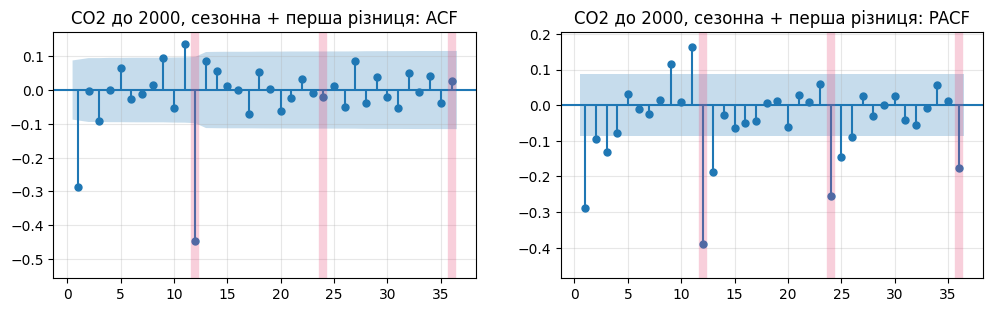

In [9]:
co2 = pd.read_csv(f"{BASE}/co2_mauna_loa.csv", parse_dates=["ds"])
past, after = co2[co2["ds"] < "2001-01-01"], co2[co2["ds"] >= "2001-01-01"]
y2, y_after = past["y"].to_numpy(), after["y"].to_numpy()
print(f"навчання: {len(past)} місяців до {past['ds'].iloc[-1]:%Y-%m}; перевірка: {len(after)} місяців до {after['ds'].iloc[-1]:%Y-%m}")
D2, d2, z2 = difference_plan(y2, m=12)
acf_pacf(z2, lags=36, title="CO2 до 2000, сезонна + перша різниця:", m=12)

**Висновок.** Знову $D = 1$, $d = 1$, і знову ACF подвійної різниці має від'ємні стрибки на лагу 1 і на
сезонному лагу 12, а на 24 і 36 — майже нічого. Це та сама структура, що в авіаліній: кандидат вручну —
$(0,1,1)(0,1,1)_{12}$. Логарифм тут не потрібен: сезонний розмах CO₂ (≈ 6 ppm) не залежить від рівня.

In [10]:
H2 = len(after)
co2_models = {
    "ARIMA вручну (0,1,1)(0,1,1)": seasonal(order=(0, 1, 1), seasonal_order=(0, 1, 1)),
    "AutoARIMA": AutoARIMA(season_length=12),
    "AutoETS": AutoETS(season_length=12),
}
co2_fc, rows = {}, []
for name, model in co2_models.items():
    fit = model.fit(y=y2)
    fc = fit.predict(h=H2, level=[95])
    co2_fc[name] = fc
    error = y_after - fc["mean"]
    rows.append({"модель": name,
                 "обрала": fit.model_.get("method") or str(ARIMASummary(fit.model_)).strip(),
                 "MAE за 25 років": np.mean(np.abs(error)),
                 f"прогноз на {after['ds'].iloc[-1]:%Y-%m}": fc["mean"][-1],
                 "95% інтервал накрив": np.mean((y_after >= fc["lo-95"]) & (y_after <= fc["hi-95"]))})
print(f"фактично у {after['ds'].iloc[-1]:%Y-%m}: {y_after[-1]:.1f} ppm")
pd.DataFrame(rows).round(2)

фактично у 2026-09: 426.1 ppm


,модель,обрала,MAE за 25 років,прогноз на 2026-09,95% інтервал накрив
0,"ARIMA вручну (0,1,1)(0,1,1)","ARIMA(0,1,1)(0,1,1)[12]",6.38,410.51,1.00
1,AutoARIMA,"ARIMA(0,1,1)(1,1,1)[12]",6.55,410.15,1.00
2,AutoETS,"ETS(A,A,A)",7.48,408.39,0.44


**Висновок.** Усі три моделі дають схожий точковий прогноз на 2026 рік — близько 408–411 ppm — і всі
недооцінюють фактичні ≈ 426 ppm приблизно на 16 ppm. MAE за 25 років у двох ARIMA трохи менша, ніж у ETS.

Різниця між моделями не в точці, а в **інтервалах**: 95% інтервали обох ARIMA накрили **всі** 309 місяців,
а інтервал ETS — менше половини. Для прогнозу на чверть століття це головний результат таблиці.

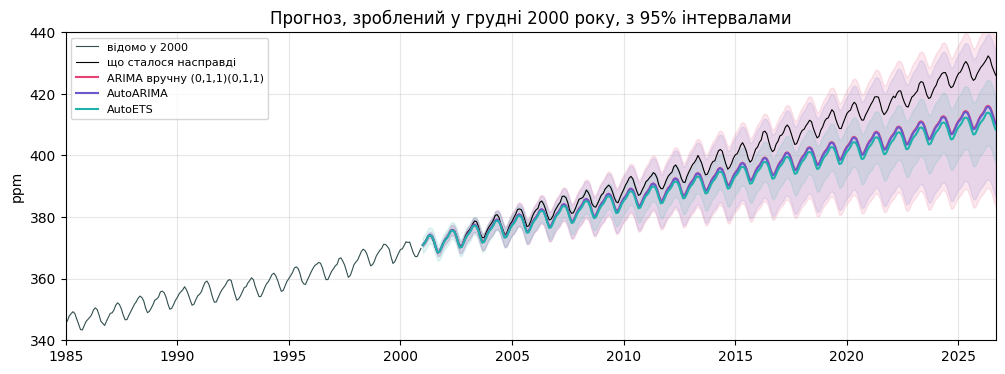

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(past["ds"], y2, color=COLOURS["actual"], linewidth=0.8, label="відомо у 2000")
ax.plot(after["ds"], y_after, color="black", linewidth=0.8, label="що сталося насправді")
for (name, fc), colour in zip(co2_fc.items(), [COLOURS["a"], COLOURS["d"], COLOURS["b"]]):
    ax.plot(after["ds"], fc["mean"], color=colour, linewidth=1.5, label=name)
    ax.fill_between(after["ds"], fc["lo-95"], fc["hi-95"], color=colour, alpha=0.12)
ax.set_xlim(pd.Timestamp("1985-01-01"), after["ds"].iloc[-1])
ax.set_ylim(340, 440)
ax.set_ylabel("ppm")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Прогноз, зроблений у грудні 2000 року, з 95% інтервалами")
plt.show()

**Висновок.** Прогнози — прямі лінії з сезонним візерунком, і фактичний ряд поступово відходить від них
угору: перші роки прогноз майже точний, далі розрив росте. Фактичні значення лишаються всередині широкого
віяла ARIMA, але виходять за вузьку смугу ETS вже на початку 2010-х.

Чому всі моделі недооцінили? Подивімося на **темп** зростання — зміну відносно того самого місяця рік тому,
усереднену за кожен рік:

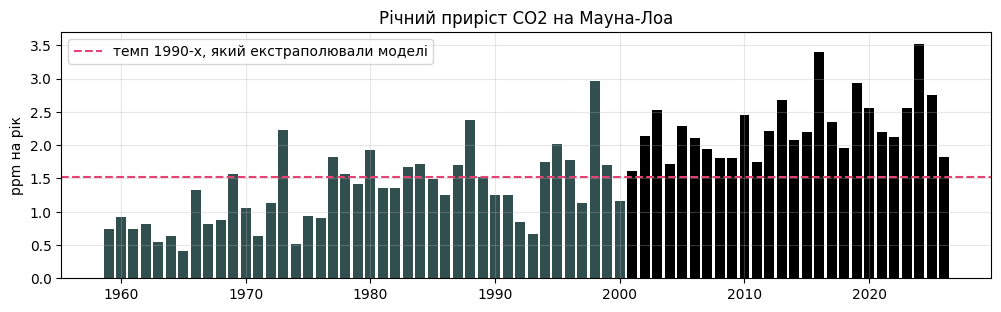

In [12]:
growth = (co2.set_index("ds")["y"].diff(12).resample("YS").mean().dropna())
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(growth.index.year, growth.values, color=[COLOURS["actual"] if y < 2001 else "black" for y in growth.index.year])
ax.axhline(growth[growth.index.year.isin(range(1991, 2001))].mean(), color=COLOURS["a"], linestyle="--",
           label="темп 1990-х, який екстраполювали моделі")
ax.set_ylabel("ppm на рік")
ax.legend(loc="upper left")
ax.set_title("Річний приріст CO2 на Мауна-Лоа")
plt.show()

**Висновок.** У 1990-х CO₂ зростав у середньому на 1,5 ppm на рік, у 2001–2026 роках — від 1,6 до 3,5 ppm,
і що ближче до сьогодення, то швидше. Модель із
$d + D = 2$ продовжує **нахил останніх років** прямою лінією. Вона правильно описала минуле, але темп
змінився: викиди прискорилися. Жодна модель, побудована лише на історії ряду, не могла цього передбачити.

### Обговорення і відповіді

**Чому інтервали ARIMA накрили всі 309 місяців, а ETS — менше половини? Що в будові моделей робить одну
настільки обережнішою?**

У ARIMA з двома різницями нахил — це випадкове блукання: модель допускає, що він може змінитися, і
невизначеність нахилу накопичується з горизонтом, тож інтервал розширюється дуже швидко. ETS(A,A,A)
оцінила $\beta \approx 0{,}003$: у минулому нахил майже не змінювався, тому модель вважає його практично
фіксованим, і її інтервал росте повільно. У минулому це було правдою, у майбутньому — ні. Вузький
інтервал, який не накриває факт, гірший за широкий, який накриває: він обіцяє впевненість, якої немає.

**Що ви сказали б політику у 2000 році — і що мусили б сказати інакше сьогодні?**

У 2000-му: «Якщо темп зростання не зміниться, у 2026 році буде близько 410 ppm. Але ось діапазон, і його
верхня межа — реальний сценарій, а не формальність». Прогноз — це умовне твердження («якщо світ не
зміниться»), а інтервал — частина відповіді, не примітка. Сьогодні: модель не помилилася щодо минулого —
змінився світ під нею. Для таких рядів екстраполяцію варто доповнювати сценаріями з причинними
змінними (викиди, економіка), а не покладатися лише на власну історію ряду.

## 3. 🏭 ARIMA проти ETS на шести австралійських галузях

Квартальне виробництво пива, тютюну, цегли, цементу, електроенергії та газу — шість рядів, одне питання:
**яка родина моделей прогнозує краще?** Шість ковзних початків, кожен на два роки вперед.

In [13]:
production = pd.read_csv(f"{BASE}/aus_production_long.csv", parse_dates=["ds"])
scores = {}
for industry in ["Beer", "Tobacco", "Bricks", "Cement", "Electricity", "Gas"]:
    df = (production.query("unique_id == @industry").dropna()
          .sort_values("ds").reset_index(drop=True))
    cv = StatsForecast(models=[AutoARIMA(season_length=4, alias="ARIMA"),
                               AutoETS(season_length=4, alias="ETS"),
                               SeasonalNaive(season_length=4, alias="snaive")],
                       freq=pd.infer_freq(df["ds"])).cross_validation(df=df, h=8, n_windows=6, step_size=4)
    cv["ARIMA + ETS"] = (cv["ARIMA"] + cv["ETS"]) / 2
    scores[industry] = (evaluate(cv.drop(columns="cutoff"), metrics=[partial(mase, seasonality=4)], train_df=df)
                        .drop(columns=["unique_id", "metric"]).iloc[0])
scores = pd.DataFrame(scores).T
scores.round(3)

,ARIMA,ETS,snaive,ARIMA + ETS
Beer,0.763,0.646,0.869,0.700
Tobacco,0.954,1.006,1.024,0.945
Bricks,1.028,1.092,1.063,1.051
Cement,1.918,1.674,1.682,1.694
Electricity,1.171,1.429,1.682,1.273
Gas,1.100,1.268,1.551,1.110


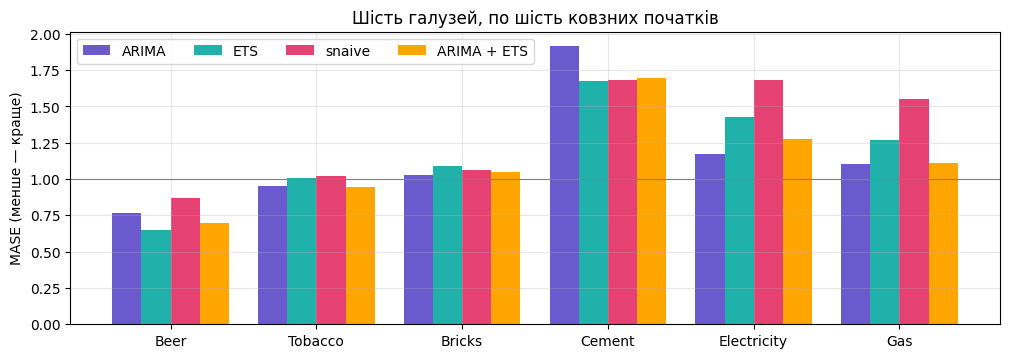

перемоги: {'ARIMA': 4, 'ETS': 2} | середнє ніколи не було гіршим за обидві моделі: True


In [14]:
fig, ax = plt.subplots(figsize=(12, 3.8))
width = 0.2
for j, (column, colour) in enumerate(zip(scores.columns, [COLOURS["d"], COLOURS["b"], COLOURS["a"], COLOURS["c"]])):
    ax.bar(np.arange(len(scores)) + (j - 1.5) * width, scores[column], width, label=column, color=colour)
ax.set_xticks(range(len(scores)), scores.index)
ax.axhline(1, color="grey", linewidth=0.8)
ax.set_ylabel("MASE (менше — краще)")
ax.legend(ncol=4)
ax.set_title("Шість галузей, по шість ковзних початків")
plt.show()

wins = (scores[["ARIMA", "ETS"]].idxmin(axis=1)).value_counts()
print("перемоги:", wins.to_dict(), "| середнє ніколи не було гіршим за обидві моделі:",
      bool((scores["ARIMA + ETS"] <= scores[["ARIMA", "ETS"]].max(axis=1)).all()))

**Висновок.**

- **ARIMA виграє на чотирьох рядах** (Tobacco, Bricks, Electricity, Gas), **ETS — на двох** (Beer, Cement).
- **Розриви несиметричні.** На Electricity ARIMA краща за ETS приблизно на 0,26 MASE, на Cement ETS краща за
  ARIMA приблизно на 0,24. Програш «не тієї» моделі на окремому ряді може бути великим.
- **Не все перевершує бенчмарк.** На Cement, Electricity, Gas і Bricks MASE > 1 для всіх моделей: два роки
  наперед на цих рядах — важке завдання. Значення понад 1 означає, що похибка більша, ніж у наївного
  прогнозу *на навчальних даних*. Порівняння із сезонним наївним прогнозом — у колонці `snaive`, і обидві
  родини його здебільшого перемагають.
- **Середнє двох моделей ніколи не гірше за обидві**: на кожному ряді воно лежить між ними, а на Tobacco
  навіть трохи краще за кращу.

### Обговорення і відповіді

**ARIMA виграє частіше, ETS — інколи, жодна не виграє скрізь. Якби завтра треба було прогнозувати сьому
галузь без часу на порівняння, що б ви обрали — і чи правильна відповідь «ту, що вигравала частіше»?**

«Ту, що частіше вигравала» — не найкраща відповідь. Частота перемог нічого не каже про те, **наскільки**
програє модель, коли програє: на Cement ARIMA мала б MASE 1,92 замість 1,67. Без валідації на конкретному
ряді найбезпечніший вибір — **середнє ARIMA і ETS**. Воно рідко буває найкращим, але ніколи не найгіршим:
його похибка не більша за похибку гіршої зі складових. Коли незрозуміло, яка модель виграє, комбінація
страхує від великого програшу. Це головна ідея наступної лекції, і тут вона вже видна на шести рядах.

## 4. 🔥 Мельбурн, січень 2014: прогноз попиту під час спеки

З 14 по 17 січня 2014 року в Мельбурні було чотири дні поспіль понад 41 °C. Оператор енергосистеми має
знати за кілька днів наперед, скільки електроенергії це потребуватиме. Це **динамічна регресія**
(тиждень 7): добовий попит на температуру, температуру², ознаку робочого дня, а похибки — ARIMA.

In [15]:
vic = pd.read_csv(f"{BASE}/vic_elec.csv", parse_dates=["ds"])
wide = vic.pivot_table(index="ds", columns="unique_id", values="y")
wide["holiday"] = vic.query("unique_id == 'Demand'").set_index("ds")["Holiday"]
daily = (wide.groupby(wide.index.date)
         .agg(demand=("Demand", "sum"), temp=("Temperature", "max"), holiday=("holiday", "max"))
         .rename_axis("ds").reset_index())
daily["ds"] = pd.to_datetime(daily["ds"])
daily["demand"] = daily["demand"] / 2000                                  # ГВт·год на добу
daily["workday"] = ((daily["ds"].dt.dayofweek < 5) & ~daily["holiday"].astype(bool)).astype(int)

origin = int(np.flatnonzero(daily["ds"] == "2014-01-06")[0])              # прогноз роблять 6 січня
H4 = 21
train4 = daily.iloc[:origin]
window = daily.iloc[origin:origin + H4]
print(f"навчання: {train4['ds'].iloc[0]:%Y-%m-%d} — {train4['ds'].iloc[-1]:%Y-%m-%d};  "
      f"найспекотніший день у навчанні: {train4['temp'].max():.1f} °C;  у вікні прогнозу: {window['temp'].max():.1f} °C")

навчання: 2012-01-01 — 2014-01-05;  найспекотніший день у навчанні: 40.6 °C;  у вікні прогнозу: 43.2 °C


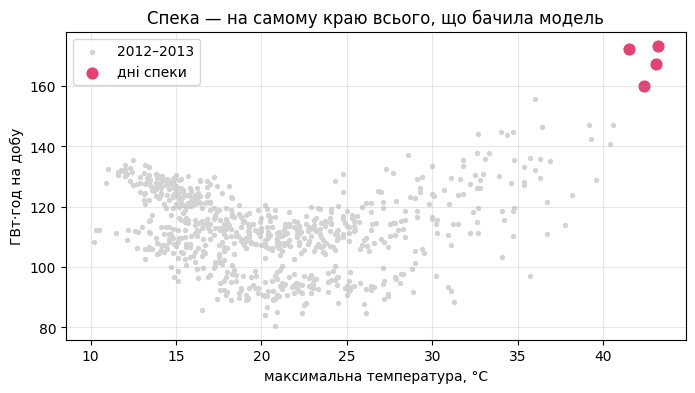

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train4["temp"], train4["demand"], s=8, color="lightgray", label="2012–2013")
heat = window[window["temp"] > 40]
ax.scatter(heat["temp"], heat["demand"], s=60, color=COLOURS["a"], label="дні спеки")
ax.set_xlabel("максимальна температура, °C")
ax.set_ylabel("ГВт·год на добу")
ax.legend()
ax.set_title("Спека — на самому краю всього, що бачила модель")
plt.show()

**Висновок.** Залежність попиту від температури має форму літери U: попит росте і в холод (опалення), і в
спеку (кондиціонери). Тому в регресії є $\text{temp}^2$. Найспекотніший день у навчальних даних — 40,6 °C, а
під час хвилі температура сягала 43,2 °C. Попит у дні спеки (рожеві точки) **вищий за все, що траплялося
раніше**. Модель мусить екстраполювати — це найслабше місце будь-якої регресії.

In [17]:
X = np.column_stack([daily["temp"], daily["temp"] ** 2, daily["workday"]])
y4 = daily["demand"].to_numpy()

with_temp = AutoARIMA(season_length=7).fit(y=y4[:origin], X=X[:origin])
fc_temp = with_temp.predict(h=H4, X=X[origin:origin + H4], level=[80])
fc_none = AutoARIMA(season_length=7).fit(y=y4[:origin]).predict(h=H4, level=[80])

actual = y4[origin:origin + H4]
print(ARIMASummary(with_temp.model_))
print(f"MAE за 21 день:  з температурою {np.mean(np.abs(actual - fc_temp['mean'])):.1f} ГВт·год,  "
      f"без неї {np.mean(np.abs(actual - fc_none['mean'])):.1f} ГВт·год")
heatwave = (window["temp"] > 40).to_numpy()
print(f"у дні спеки:  фактично {actual[heatwave].mean():.0f},  з температурою "
      f"{fc_temp['mean'][heatwave].mean():.0f},  без неї {fc_none['mean'][heatwave].mean():.0f} ГВт·год на добу")

Regression with ARIMA(4,1,1)(2,0,2)[7] errors
MAE за 21 день:  з температурою 14.2 ГВт·год,  без неї 19.2 ГВт·год
у дні спеки:  фактично 168,  з температурою 138,  без неї 105 ГВт·год на добу


**Висновок.**

- Для похибок регресії `AutoARIMA` обрала сезонну модель з періодом 7: тижневий ритм, який не пояснили
  ознака робочого дня і температура, переходить у похибки.
- **За 21 день** температура зменшує MAE приблизно на чверть: з ≈ 19 до ≈ 14 ГВт·год.
- **У дні спеки** фактичний попит — близько 168 ГВт·год на добу. Модель з температурою дає ≈ 138, без неї —
  ≈ 105. Розрив скоротився з ≈ 63 до ≈ 30: температура закриває **приблизно половину**, але не весь.

Важливо: тут у модель подано **фактичну** температуру, тобто це прогноз ex post (тиждень 7). Справжній
прогноз 6 січня мав би лише прогноз погоди, і похибка була б більшою.

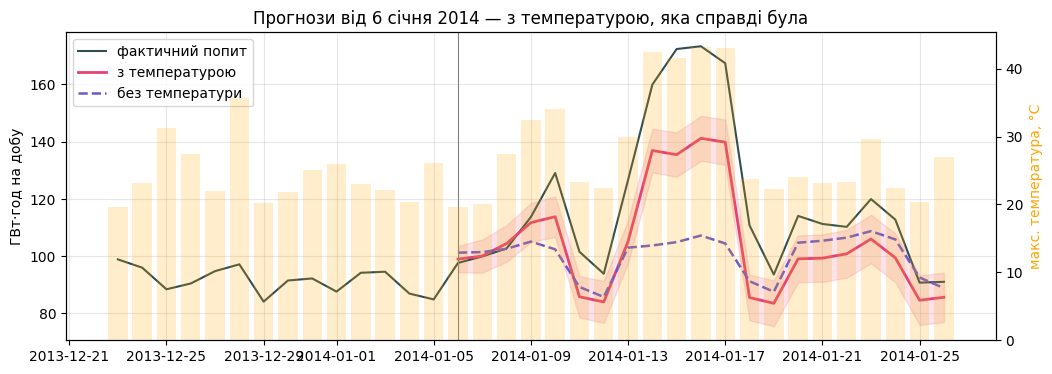

In [18]:
fig, ax1 = plt.subplots(figsize=(12, 4))
days = daily["ds"].iloc[origin - 14:origin + H4]
ax1.plot(days, y4[origin - 14:origin + H4], color=COLOURS["actual"], linewidth=1.5, label="фактичний попит")
ax1.plot(window["ds"], fc_temp["mean"], color=COLOURS["a"], linewidth=2, label="з температурою")
ax1.fill_between(window["ds"], fc_temp["lo-80"], fc_temp["hi-80"], color=COLOURS["a"], alpha=0.15)
ax1.plot(window["ds"], fc_none["mean"], "--", color=COLOURS["d"], linewidth=1.8, label="без температури")
ax1.axvline(window["ds"].iloc[0], color="grey", linewidth=0.8)
ax1.set_ylabel("ГВт·год на добу")
ax2 = ax1.twinx()
ax2.bar(days, daily["temp"].iloc[origin - 14:origin + H4], color=COLOURS["c"], alpha=0.2, width=0.8)
ax2.set_ylabel("макс. температура, °C", color=COLOURS["c"])
ax2.grid(False)
ax1.legend(loc="upper left")
ax1.set_title("Прогнози від 6 січня 2014 — з температурою, яка справді була")
plt.show()

**Висновок.** Модель без температури бачить лише тижневий ритм і не знає про спеку: її прогноз — та сама
пилка, що й до 6 січня. Модель з температурою реагує на хвилю, але недостатньо: у дні спеки вона нижча за
факт на 23–37 ГВт·год на добу.

Важливіше інше: перші чотири дні прогноз точний, а **з 10 по 24 січня фактичний попит вищий за верхню межу
80% інтервалу 15 днів поспіль**, зокрема і після хвилі, коли температура повернулася до 22–24 °C (недооцінка
≈ 9–25 ГВт·год). Дві проблеми, а не одна: модель м'яко реагує на екстремальну спеку, і її інтервал занадто
вузький — він не враховує, що похибки в такі тижні йдуть серіями в один бік.

На практиці оператор не знає і температури — лише прогноз погоди. Тому корисний результат — **набір
сценаріїв**: та сама модель, якій подають три варіанти наступних трьох тижнів.

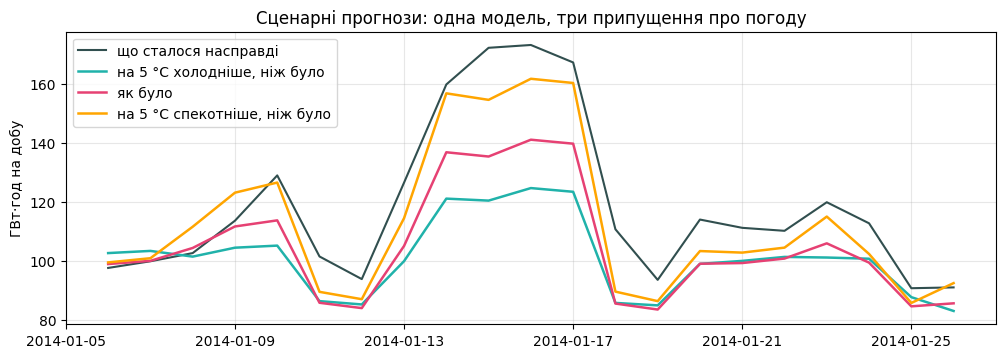

In [19]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(window["ds"], actual, color=COLOURS["actual"], linewidth=1.5, label="що сталося насправді")
for shift, colour, label in [(-5, COLOURS["b"], "на 5 °C холодніше, ніж було"), (0, COLOURS["a"], "як було"),
                             (5, COLOURS["c"], "на 5 °C спекотніше, ніж було")]:
    t = window["temp"].to_numpy() + shift
    Xs = np.column_stack([t, t ** 2, window["workday"]])
    ax.plot(window["ds"], with_temp.predict(h=H4, X=Xs)["mean"], color=colour, linewidth=1.8, label=label)
ax.set_ylabel("ГВт·год на добу")
ax.legend(loc="upper left")
ax.set_title("Сценарні прогнози: одна модель, три припущення про погоду")
plt.show()

### Обговорення і відповіді

**Температура закриває приблизно половину розриву в дні спеки — і не більше. Чому?**

1. **Екстраполяція.** Хвиля спекотніша за будь-який день у навчальних даних (43,2 °C проти 40,6 °C).
   Квадратичну криву оцінено на діапазоні, де спекотних днів мало; за його межами вона просто
   продовжує параболу, а не реальну залежність.
2. **Нелінійність, якої немає в моделі.** Кондиціонери вмикаються не поступово: кожен наступний спекотний
   день поспіль будинки нагріваються сильніше, і вмикаються майже всі. Попит росте різкіше, ніж
   парабола від однієї денної температури.

Сценарний графік це підтверджує: найближча до факту — помаранчева лінія, погода, зроблена **на 5 °C
спекотнішою, ніж була насправді**, і навіть вона в пікові дні нижча за факт. Модель реагує на спеку надто м'яко саме на верхньому краю.

**Чи достатньо добрий прогноз з температурою, щоб за ним планувати? Що додати до моделі перед наступним
літом?**

Як є — ні. Він кращий за прогноз без температури (MAE ≈ 14 проти ≈ 19), але недооцінює попит на ≈ 30
ГВт·год на добу саме тоді, коли система найбільш навантажена, а його 80% інтервал не накрив факт 15 днів
із 21. План за верхньою межею такого інтервалу — це ризик відключень. Що додати:

- окремий ефект для днів понад ~35 °C — кусково-лінійний член, як у тижні 5, замість самої параболи;
- кількість спекотних днів поспіль або температуру попереднього дня — накопичення тепла;
- дані про попередні хвилі спеки (довша історія), щоб модель бачила такі дні в навчанні;
- для планування — сценарії з прогнозами погоди і запасом на верхньому краю, а не одну точку.

## Що з цього взяти на сьогоднішню лабораторну

| Кейс | Хід | Що вирішило |
|---|---|---|
| ✈️ Авіалінії | log, $D = 1$, $d = 1$; стрибки на 1 і 12 → (0,1,1)(0,1,1) | рука, stepwise і повний пошук збіглися; ковзний початок підтвердив |
| 🌍 CO₂ | та сама структура, на 25 років уперед | світ змінився: чесні інтервали важили більше за точку |
| 🏭 Галузі | ARIMA проти ETS на шести рядах | жодна не виграє скрізь; середнє ніколи не програло обом |
| 🔥 Спека | регресія з ARIMA-похибками | предиктор допомагає лише в межах діапазону навчальних даних |

**Lab 7** — це кейс 1 на вашому власному ряді: продиференціювати, прочитати $p, q$ **і** $P, Q$ з ACF і PACF,
порівняти з `AutoARIMA` за AICc і на ковзному початку, перевірити залишки з $p + q + P + Q$ ступенями
свободи, здати прогноз.